In [ ]:

import pandas as pd

file_path = "/content/individual+household+electric+power+consumption.zip"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset loaded successfully!
Number of rows and columns: (2075259, 9)

First 5 rows:
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [ ]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Data types:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Missing values in each column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Duplicate rows: 0


In [ ]:

# 1. Combine Date and Time into a proper timestamp
df["Datetime"] = pd.to_datetime(
df["Date"] + " " + df["Time"],
format="%d/%m/%Y %H:%M:%S",
errors="coerce"
)

# 2. Identify numeric measurement columns
numeric_cols = df.select_dtypes(include="number").columns

# 3. Count missing measurements in each row
missing_per_row = df[numeric_cols].isna().sum(axis=1)

print("Rows where all 7 measurements are missing:",
      (missing_per_row == len(numeric_cols)).sum())

print("Rows where only some measurements are missing:",
      ((missing_per_row > 0) &
       (missing_per_row < len(numeric_cols))).sum())

# 4. Check timestamps
print("\nInvalid timestamps:", df["Datetime"].isna().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

# 5. Check the time range
print("\nFirst timestamp:", df["Datetime"].min())
print("Last timestamp:", df["Datetime"].max())

# 6. Inspect basic statistics
print("\nMeasurement summary:")
print(df[numeric_cols].describe().round(2))

Rows where all 7 measurements are missing: 25979
Rows where only some measurements are missing: 0

Invalid timestamps: 0
Duplicate timestamps: 0

First timestamp: 2006-12-16 17:24:00
Last timestamp: 2010-11-26 21:02:00

Measurement summary:
       Global_active_power  Global_reactive_power     Voltage  \
count           2049280.00             2049280.00  2049280.00   
mean                  1.09                   0.12      240.84   
std                   1.06                   0.11        3.24   
min                   0.08                   0.00      223.20   
25%                   0.31                   0.05      238.99   
50%                   0.60                   0.10      241.01   
75%                   1.53                   0.19      242.89   
max                  11.12                   1.39      254.15   

       Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
count        2049280.00      2049280.00      2049280.00      2049280.00  
mean               4.63  

In [ ]:

import os

print(os.listdir("/content"))

['.config', 'individual+household+electric+power+consumption.zip', 'sample_data']


In [ ]:

from google.colab import files

uploaded = files.upload()

Saving individual+household+electric+power+consumption.zip to individual+household+electric+power+consumption.zip


In [ ]:

# Count missing rows by date
missing_dates = df.loc[
    df["Global_active_power"].isna(),
    "Date"
].value_counts().sort_index()

print("Number of dates affected:",
      len(missing_dates))

print("\nFirst 10 dates with missing data:")
print(missing_dates.head(10))

print("\nLast 10 dates with missing data:")
print(missing_dates.tail(10))

Number of dates affected: 82

First 10 dates with missing data:
Date
1/2/2009      38
1/3/2009       1
1/6/2007       1
1/8/2007      21
10/11/2008     6
10/12/2008    70
10/12/2009     2
10/2/2010      1
10/5/2009      1
10/7/2009      4
Name: count, dtype: int64

Last 10 dates with missing data:
Date
29/6/2007       1
29/6/2010       1
30/12/2006      2
30/4/2007     864
30/9/2009       2
31/8/2008       1
4/8/2008        1
6/6/2007        1
9/11/2009       1
9/6/2007       38
Name: count, dtype: int64


In [ ]:

# Count missing measurements for each date
missing_dates = df.loc[
    df["Global_active_power"].isna(),
    ["Date", "Datetime"]
].copy()

missing_dates["Date"] = pd.to_datetime(
    missing_dates["Date"],
    format="%d/%m/%Y"
)

daily_missing = (
    missing_dates.groupby("Date")
    .size()
    .sort_values(ascending=False)
)

print("Top 10 dates with the most missing measurements:")
print(daily_missing.head(10))

print("\nTotal missing rows:", len(missing_dates))
print("Dates affected:", daily_missing.size)

Top 10 dates with the most missing measurements:
Date
2007-04-29    1440
2009-06-14    1440
2010-01-13    1440
2010-08-21    1440
2010-09-27    1440
2010-09-26    1440
2010-08-20    1440
2010-08-18    1440
2010-08-19    1440
2007-04-28    1419
dtype: int64

Total missing rows: 25979
Dates affected: 82


In [ ]:

# Keep the original dataset unchanged
clean_df = df.copy()

# Identify the seven measurement columns
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Count rows where every measurement is missing
missing_rows = clean_df[measurement_cols].isna().all(axis=1).sum()

# Remove only rows where all seven measurements are missing
clean_df = clean_df.dropna(
    subset=measurement_cols,
    how="all"
).copy()

print("Original rows:", len(df))
print("Rows removed:", missing_rows)
print("Cleaned rows:", len(clean_df))
print("Remaining rows with all measurements missing:",
      clean_df[measurement_cols].isna().all(axis=1).sum())

Original rows: 2075259
Rows removed: 25979
Cleaned rows: 2049280
Remaining rows with all measurements missing: 0


In [ ]:

# Check the cleaned dataset
print("Dataset shape:", clean_df.shape)

print("\nMissing values in each column:")
print(clean_df.isna().sum())

print("\nDuplicate timestamps:",
      clean_df["Datetime"].duplicated().sum())

print("\nDate range:")
print("Start:", clean_df["Datetime"].min())
print("End:", clean_df["Datetime"].max())

print("\nSummary of active power:")
print(clean_df["Global_active_power"].describe().round(2))

Dataset shape: (2049280, 10)

Missing values in each column:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Datetime                 0
dtype: int64

Duplicate timestamps: 0

Date range:
Start: 2006-12-16 17:24:00
End: 2010-11-26 21:02:00

Summary of active power:
count    2049280.00
mean           1.09
std            1.06
min            0.08
25%            0.31
50%            0.60
75%            1.53
max           11.12
Name: Global_active_power, dtype: float64


In [ ]:

# Create a separate analysis dataset
analysis_df = clean_df.copy()

# Extract time-based features
analysis_df["Year"] = analysis_df["Datetime"].dt.year
analysis_df["Month"] = analysis_df["Datetime"].dt.month
analysis_df["DayOfWeek"] = analysis_df["Datetime"].dt.day_name()
analysis_df["Hour"] = analysis_df["Datetime"].dt.hour

print("Time features created successfully!")

print("\nPreview:")
print(
    analysis_df[
        ["Datetime", "Global_active_power",
         "Year", "Month", "DayOfWeek", "Hour"]
    ].head(10)
)

Time features created successfully!

Preview:
             Datetime  Global_active_power  Year  Month DayOfWeek  Hour
0 2006-12-16 17:24:00                4.216  2006     12  Saturday    17
1 2006-12-16 17:25:00                5.360  2006     12  Saturday    17
2 2006-12-16 17:26:00                5.374  2006     12  Saturday    17
3 2006-12-16 17:27:00                5.388  2006     12  Saturday    17
4 2006-12-16 17:28:00                3.666  2006     12  Saturday    17
5 2006-12-16 17:29:00                3.520  2006     12  Saturday    17
6 2006-12-16 17:30:00                3.702  2006     12  Saturday    17
7 2006-12-16 17:31:00                3.700  2006     12  Saturday    17
8 2006-12-16 17:32:00                3.668  2006     12  Saturday    17
9 2006-12-16 17:33:00                3.662  2006     12  Saturday    17


In [ ]:

# Calculate average power consumption for each hour
hourly_usage = (
    analysis_df.groupby("Hour")["Global_active_power"]
    .mean()
    .reset_index()
)

hourly_usage = hourly_usage.rename(
    columns={"Global_active_power": "Average_Power_kW"}
)

hourly_usage["Average_Power_kW"] = (
    hourly_usage["Average_Power_kW"].round(3)
)

print("Average electricity consumption by hour:")
print(hourly_usage.to_string(index=False))

# Identify peak and lowest average usage hours
peak_hour = hourly_usage.loc[
    hourly_usage["Average_Power_kW"].idxmax()
]

lowest_hour = hourly_usage.loc[
    hourly_usage["Average_Power_kW"].idxmin()
]

print("\nPeak average usage hour:",
      int(peak_hour["Hour"]),
      "with", peak_hour["Average_Power_kW"], "kW")

print("Lowest average usage hour:",
      int(lowest_hour["Hour"]),
      "with", lowest_hour["Average_Power_kW"], "kW")

Average electricity consumption by hour:
 Hour  Average_Power_kW
    0             0.659
    1             0.539
    2             0.481
    3             0.445
    4             0.444
    5             0.454
    6             0.792
    7             1.502
    8             1.461
    9             1.332
   10             1.261
   11             1.246
   12             1.207
   13             1.145
   14             1.083
   15             0.991
   16             0.949
   17             1.055
   18             1.326
   19             1.733
   20             1.899
   21             1.878
   22             1.413
   23             0.902

Peak average usage hour: 20 with 1.899 kW
Lowest average usage hour: 4 with 0.444 kW


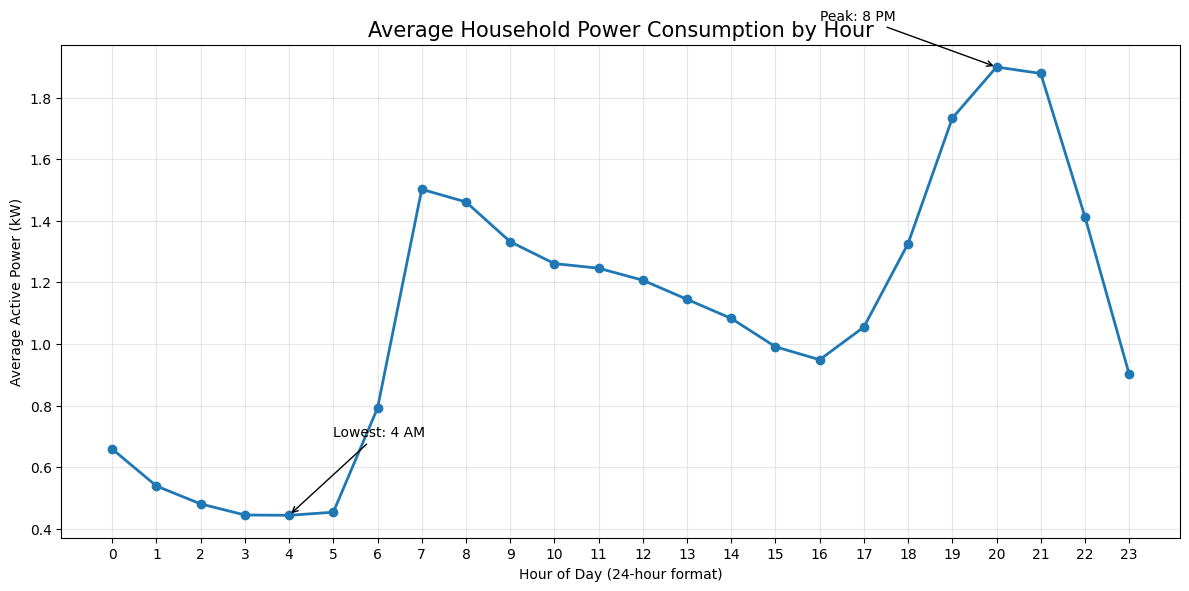

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_usage["Hour"],
    hourly_usage["Average_Power_kW"],
    marker="o",
    linewidth=2
)

plt.title(
    "Average Household Power Consumption by Hour",
    fontsize=15
)
plt.xlabel("Hour of Day (24-hour format)")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

# Highlight the peak and lowest average usage hours
plt.annotate(
    "Peak: 8 PM",
    xy=(20, 1.899),
    xytext=(16, 2.05),
    arrowprops=dict(arrowstyle="->")
)

plt.annotate(
    "Lowest: 4 AM",
    xy=(4, 0.444),
    xytext=(5, 0.7),
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.show()

In [ ]:

# Define the correct weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate average power consumption by weekday
weekday_usage = (
    analysis_df.groupby("DayOfWeek")["Global_active_power"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

weekday_usage = weekday_usage.rename(
    columns={"Global_active_power": "Average_Power_kW"}
)

weekday_usage["Average_Power_kW"] = (
    weekday_usage["Average_Power_kW"].round(3)
)

print("Average power consumption by day:")
print(weekday_usage.to_string(index=False))

# Identify the highest and lowest average days
print("\nHighest average usage day:")
print(weekday_usage.loc[
    weekday_usage["Average_Power_kW"].idxmax()
].to_string())

print("\nLowest average usage day:")
print(weekday_usage.loc[
    weekday_usage["Average_Power_kW"].idxmin()
].to_string())

Average power consumption by day:
DayOfWeek  Average_Power_kW
   Monday             1.000
  Tuesday             1.070
Wednesday             1.083
 Thursday             0.982
   Friday             1.043
 Saturday             1.248
   Sunday             1.220

Highest average usage day:
DayOfWeek           Saturday
Average_Power_kW       1.248

Lowest average usage day:
DayOfWeek           Thursday
Average_Power_kW       0.982


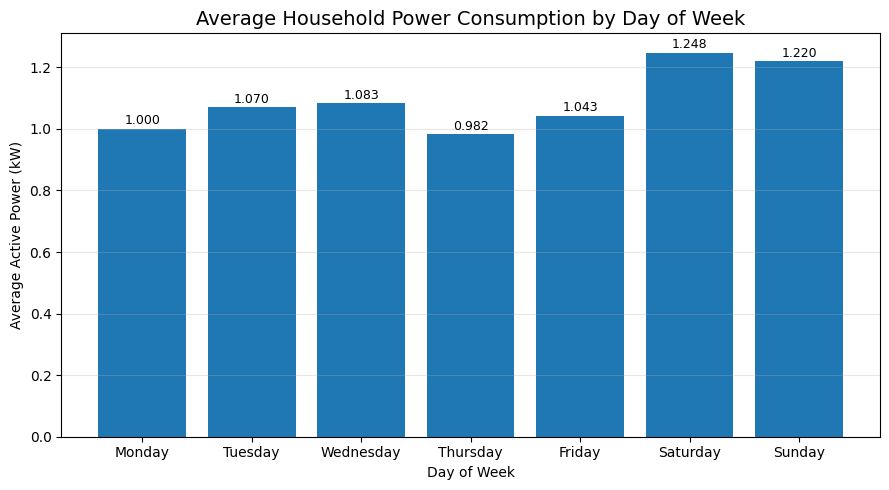

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    weekday_usage["DayOfWeek"],
    weekday_usage["Average_Power_kW"]
)

plt.title(
    "Average Household Power Consumption by Day of Week",
    fontsize=14
)
plt.xlabel("Day of Week")
plt.ylabel("Average Active Power (kW)")
plt.grid(axis="y", alpha=0.3)

# Label each bar with its value
for i, value in enumerate(weekday_usage["Average_Power_kW"]):
    plt.text(i, value + 0.015, f"{value:.3f}",
             ha="center", fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:

# Calculate average power by calendar month
monthly_usage = (
    analysis_df.groupby("Month")["Global_active_power"]
    .mean()
    .reset_index()
)

monthly_usage = monthly_usage.rename(
    columns={"Global_active_power": "Average_Power_kW"}
)

monthly_usage["Average_Power_kW"] = (
    monthly_usage["Average_Power_kW"].round(3)
)

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_usage["MonthName"] = monthly_usage["Month"].map(month_names)

print("Average power consumption by calendar month:")
print(
    monthly_usage[
        ["MonthName", "Average_Power_kW"]
    ].to_string(index=False)
)

# Identify highest and lowest average months
highest_month = monthly_usage.loc[
    monthly_usage["Average_Power_kW"].idxmax()
]

lowest_month = monthly_usage.loc[
    monthly_usage["Average_Power_kW"].idxmin()
]

print("\nHighest average month:",
      highest_month["MonthName"],
      "-", highest_month["Average_Power_kW"], "kW")

print("Lowest average month:",
      lowest_month["MonthName"],
      "-", lowest_month["Average_Power_kW"], "kW")


Average power consumption by calendar month:
MonthName  Average_Power_kW
  January             1.462
 February             1.300
    March             1.231
    April             1.047
      May             1.030
     June             0.909
     July             0.700
   August             0.573
September             0.976
  October             1.137
 November             1.292
 December             1.490

Highest average month: December - 1.49 kW
Lowest average month: August - 0.573 kW


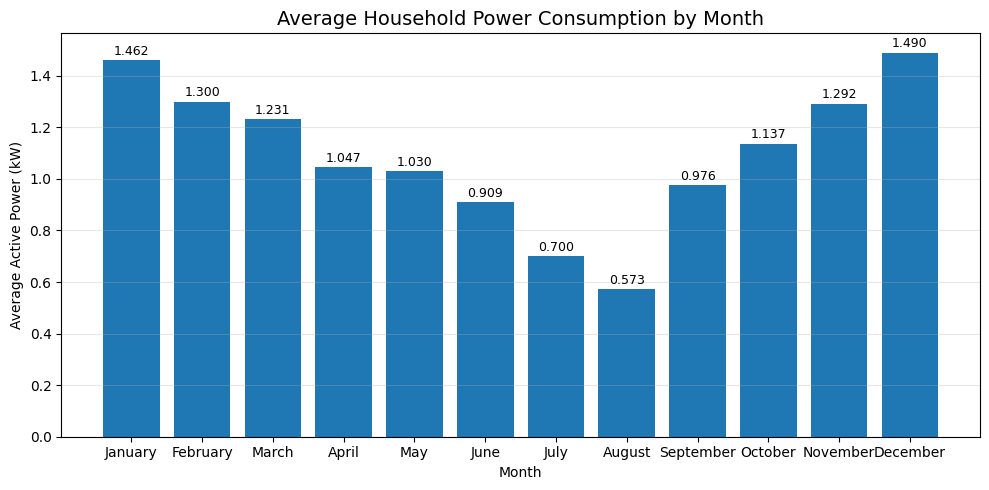

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_usage["MonthName"],
    monthly_usage["Average_Power_kW"]
)

plt.title(
    "Average Household Power Consumption by Month",
    fontsize=14
)
plt.xlabel("Month")
plt.ylabel("Average Active Power (kW)")
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(monthly_usage["Average_Power_kW"]):
    plt.text(
        i, value + 0.02, f"{value:.3f}",
        ha="center", fontsize=9
    )

plt.tight_layout()
plt.show()


In [ ]:

# Select the three sub-metering columns
submeter_cols = [
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Calculate average readings for each category
submeter_usage = (
    analysis_df[submeter_cols]
    .mean()
    .reset_index()
)

submeter_usage.columns = [
    "Category", "Average_Wh_per_minute"
]

# Make category names easier to read
submeter_usage["Category"] = (
    submeter_usage["Category"]
    .str.replace("Sub_metering_", "Sub-metering ")
)

submeter_usage["Average_Wh_per_minute"] = (
    submeter_usage["Average_Wh_per_minute"].round(3)
)

print("Average sub-metering readings:")
print(submeter_usage.to_string(index=False))


Average sub-metering readings:
      Category  Average_Wh_per_minute
Sub-metering 1                  1.122
Sub-metering 2                  1.299
Sub-metering 3                  6.458


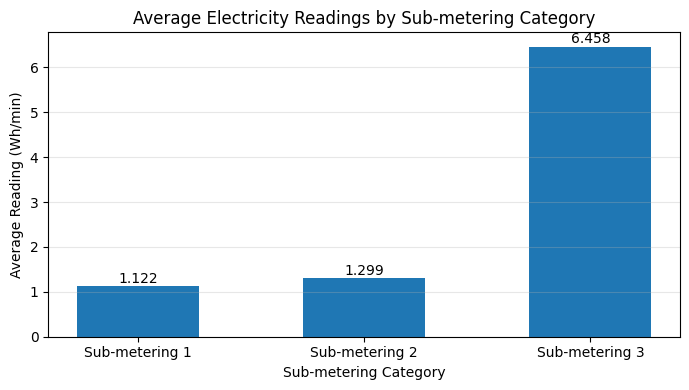

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(submeter_usage)) * 0.65

plt.figure(figsize=(7, 4))

plt.bar(
    x,
    submeter_usage["Average_Wh_per_minute"],
    width=0.35

)

plt.xticks(x, submeter_usage["Category"])
plt.title("Average Electricity Readings by Sub-metering Category")
plt.xlabel("Sub-metering Category")
plt.ylabel("Average Reading (Wh/min)")
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(submeter_usage["Average_Wh_per_minute"]):
    plt.text(x[i], value + 0.08, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()


In [ ]:

# Calculate energy consumed in each one-minute interval
analysis_df["Energy_kWh"] = (
    analysis_df["Global_active_power"] / 60
)

# Calculate daily energy consumption
daily_usage = (
    analysis_df.groupby(analysis_df["Datetime"].dt.date)["Energy_kWh"]
    .sum()
    .reset_index()
)

daily_usage.columns = ["Date", "Daily_Energy_kWh"]

daily_usage["Daily_Energy_kWh"] = (
    daily_usage["Daily_Energy_kWh"].round(2)
)

print("Daily energy consumption:")
print(daily_usage.head(10).to_string(index=False))

print("\nAverage daily energy:",
      round(daily_usage["Daily_Energy_kWh"].mean(), 2), "kWh")

print("\nHighest daily energy consumption:")
print(daily_usage.loc[
    daily_usage["Daily_Energy_kWh"].idxmax()
].to_string())

print("\nLowest daily energy consumption:")
print(daily_usage.loc[
    daily_usage["Daily_Energy_kWh"].idxmin()
].to_string())


Daily energy consumption:
      Date  Daily_Energy_kWh
2006-12-16             20.15
2006-12-17             56.51
2006-12-18             36.73
2006-12-19             27.77
2006-12-20             37.10
2006-12-21             28.61
2006-12-22             39.02
2006-12-23             79.56
2006-12-24             42.50
2006-12-25             45.72

Average daily energy: 26.02 kWh

Highest daily energy consumption:
Date                2006-12-23
Daily_Energy_kWh         79.56

Lowest daily energy consumption:
Date                2009-06-13
Daily_Energy_kWh          0.24


In [ ]:

# Count available readings for each day
daily_readings = (
    analysis_df.groupby(analysis_df["Datetime"].dt.date)
    .size()
    .reset_index(name="Available_Readings")
)

daily_readings.columns = ["Date", "Available_Readings"]

# Add reading counts to daily energy totals
daily_check = daily_usage.merge(
    daily_readings,
    on="Date",
    how="left"
)

daily_check["Missing_Readings"] = (
    1440 - daily_check["Available_Readings"]
)

print("Days with the fewest available readings:")
print(
    daily_check.sort_values("Available_Readings")
    .head(10)
    .to_string(index=False)
)

print("\nDays with all 1440 readings:",
      (daily_check["Available_Readings"] == 1440).sum())

print("Total days:", len(daily_check))


Days with the fewest available readings:
      Date  Daily_Energy_kWh  Available_Readings  Missing_Readings
2007-04-28              0.38                  21              1419
2009-06-13              0.24                  30              1410
2010-08-22              1.56                 152              1288
2010-03-20              2.20                 232              1208
2010-09-25              1.77                 236              1204
2010-09-28              7.84                 287              1153
2010-01-14             10.31                 298              1142
2006-12-16             20.15                 396              1044
2009-08-13             10.11                 549               891
2007-04-30              7.01                 576               864

Days with all 1440 readings: 1358
Total days: 1433


In [ ]:
# Keep only complete days
complete_daily_usage = daily_check[
    daily_check["Available_Readings"] == 1440
].copy()

print("Complete days:", len(complete_daily_usage))

print("\nAverage daily energy consumption:",
      round(complete_daily_usage["Daily_Energy_kWh"].mean(), 2),
      "kWh")

print("\nHighest daily energy consumption:")
print(
    complete_daily_usage.loc[
        complete_daily_usage["Daily_Energy_kWh"].idxmax()
    ]
)

print("\nLowest daily energy consumption:")
print(
    complete_daily_usage.loc[
        complete_daily_usage["Daily_Energy_kWh"].idxmin()
    ]
)

Complete days: 1358

Average daily energy consumption: 25.98 kWh

Highest daily energy consumption:
Date                  2006-12-23
Daily_Energy_kWh           79.56
Available_Readings          1440
Missing_Readings               0
Name: 7, dtype: object

Lowest daily energy consumption:
Date                  2008-08-25
Daily_Energy_kWh            4.17
Available_Readings          1440
Missing_Readings               0
Name: 617, dtype: object


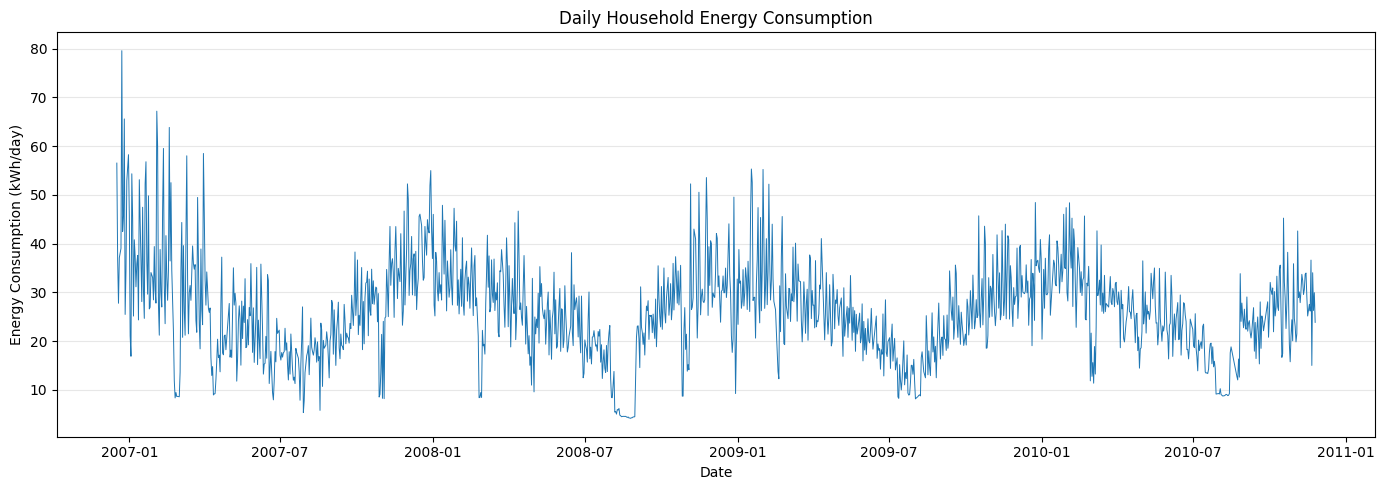

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    complete_daily_usage["Date"],
    complete_daily_usage["Daily_Energy_kWh"],
    linewidth=0.7
)

plt.title("Daily Household Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh/day)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Find the 10 days with the highest energy consumption
top_10_days = (
    complete_daily_usage
    .sort_values("Daily_Energy_kWh", ascending=False)
    .head(10)
)

print(top_10_days[
    ["Date", "Daily_Energy_kWh"]
].to_string(index=False))

      Date  Daily_Energy_kWh
2006-12-23             79.56
2007-02-03             67.16
2006-12-26             65.57
2007-02-18             63.83
2007-02-04             59.93
2007-02-11             59.52
2007-03-31             58.49
2006-12-31             58.24
2007-03-11             58.01
2007-01-21             56.79


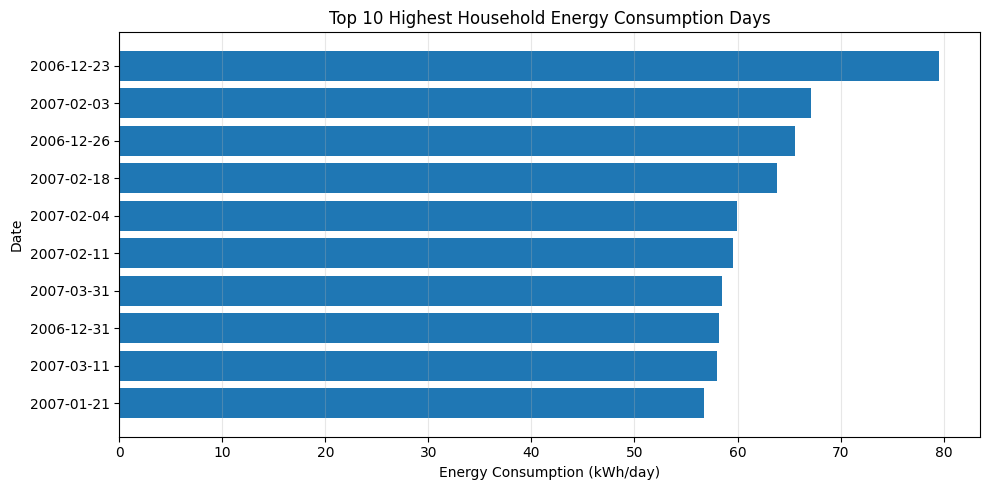

In [ ]:
import matplotlib.pyplot as plt

top_10_sorted = top_10_days.sort_values(
    "Daily_Energy_kWh", ascending=True
)

plt.figure(figsize=(10, 5))

plt.barh(
    top_10_sorted["Date"].astype(str),
    top_10_sorted["Daily_Energy_kWh"]
)

plt.title("Top 10 Highest Household Energy Consumption Days")
plt.xlabel("Energy Consumption (kWh/day)")
plt.ylabel("Date")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate the average daily energy consumption
average_daily = complete_daily_usage["Daily_Energy_kWh"].mean()

# Add a column showing consumption relative to the average
top_10_days = top_10_days.copy()

top_10_days["Times_Average"] = (
    top_10_days["Daily_Energy_kWh"] / average_daily
).round(2)

print("Average daily consumption:",
      round(average_daily, 2), "kWh")

print("\nTop 10 days compared with the average:")
print(
    top_10_days[
        ["Date", "Daily_Energy_kWh", "Times_Average"]
    ].to_string(index=False)
)

Average daily consumption: 25.98 kWh

Top 10 days compared with the average:
      Date  Daily_Energy_kWh  Times_Average
2006-12-23             79.56           3.06
2007-02-03             67.16           2.59
2006-12-26             65.57           2.52
2007-02-18             63.83           2.46
2007-02-04             59.93           2.31
2007-02-11             59.52           2.29
2007-03-31             58.49           2.25
2006-12-31             58.24           2.24
2007-03-11             58.01           2.23
2007-01-21             56.79           2.19


In [ ]:
yearly_usage = (
    analysis_df.groupby("Year")["Global_active_power"]
    .mean()
    .reset_index()
)

yearly_usage = yearly_usage.rename(
    columns={"Global_active_power": "Average_Power_kW"}
)

yearly_usage["Average_Power_kW"] = (
    yearly_usage["Average_Power_kW"].round(3)
)

print(yearly_usage.to_string(index=False))

 Year  Average_Power_kW
 2006             1.901
 2007             1.117
 2008             1.072
 2009             1.079
 2010             1.061


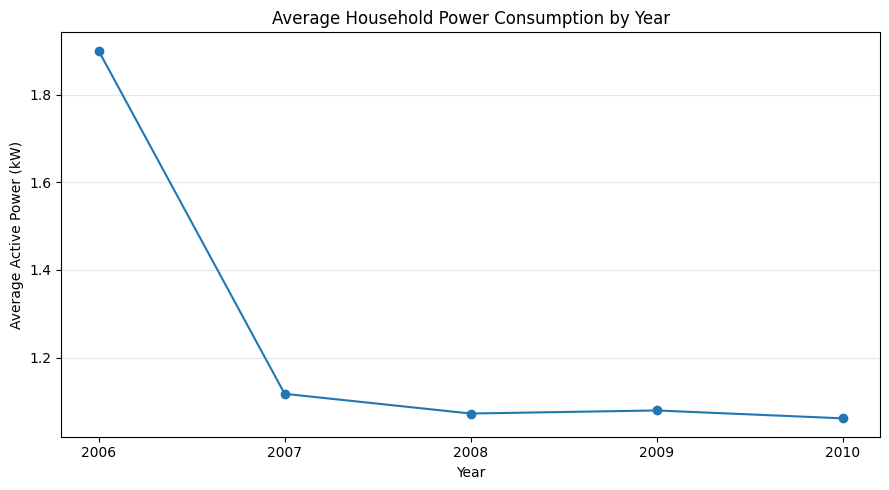

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    yearly_usage["Year"],
    yearly_usage["Average_Power_kW"],
    marker="o"
)

plt.title("Average Household Power Consumption by Year")
plt.xlabel("Year")
plt.ylabel("Average Active Power (kW)")
plt.xticks(yearly_usage["Year"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
analysis_df["Is_Weekend"] = analysis_df["Datetime"].dt.dayofweek >= 5

weekend_comparison = (
    analysis_df.groupby("Is_Weekend")["Global_active_power"]
    .mean()
    .reset_index()
)

weekend_comparison["Day_Type"] = weekend_comparison["Is_Weekend"].map({
    False: "Weekday",
    True: "Weekend"
})

weekend_comparison = weekend_comparison.rename(
    columns={"Global_active_power": "Average_Power_kW"}
)

weekend_comparison["Average_Power_kW"] = (
    weekend_comparison["Average_Power_kW"].round(3)
)

weekday_avg = weekend_comparison.loc[
    weekend_comparison["Day_Type"] == "Weekday",
    "Average_Power_kW"
].iloc[0]

weekend_avg = weekend_comparison.loc[
    weekend_comparison["Day_Type"] == "Weekend",
    "Average_Power_kW"
].iloc[0]

percentage_difference = (
    (weekend_avg - weekday_avg) / weekday_avg
) * 100

print(weekend_comparison[[
    "Day_Type", "Average_Power_kW"
]].to_string(index=False))

print("\nWeekend vs weekday difference:",
      round(percentage_difference, 2), "%")

Day_Type  Average_Power_kW
 Weekday             1.035
 Weekend             1.234

Weekend vs weekday difference: 19.23 %


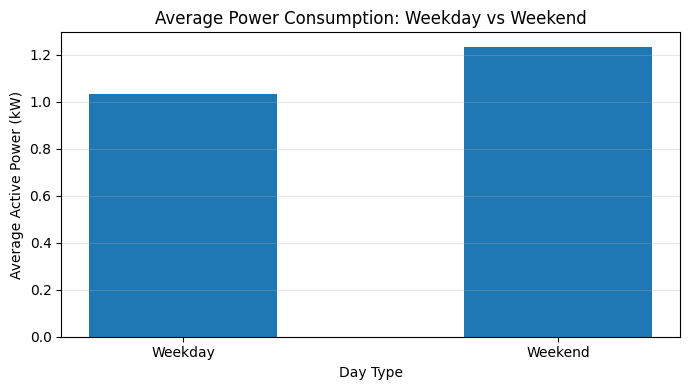

In [ ]:
import matplotlib.pyplot as plt

# Move the bars closer together
x_positions = [0, 0.2]

plt.figure(figsize=(7, 4))

plt.bar(
    x_positions,
    weekend_comparison["Average_Power_kW"],
    width=0.1
)

plt.xticks(x_positions, weekend_comparison["Day_Type"])

plt.title("Average Power Consumption: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Active Power (kW)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate key project metrics
average_power = analysis_df["Global_active_power"].mean()

peak_hour = hourly_usage.loc[
    hourly_usage["Average_Power_kW"].idxmax(), "Hour"
]

lowest_hour = hourly_usage.loc[
    hourly_usage["Average_Power_kW"].idxmin(), "Hour"
]

highest_month = monthly_usage.loc[
    monthly_usage["Average_Power_kW"].idxmax(), "MonthName"
]

highest_submeter = submeter_usage.loc[
    submeter_usage["Average_Wh_per_minute"].idxmax(), "Category"
]

weekend_difference = percentage_difference

print("===== ENERGY CONSUMPTION KPI SUMMARY =====")
print(f"Average active power: {average_power:.3f} kW")
print(f"Peak average consumption hour: {int(peak_hour):02d}:00")
print(f"Lowest average consumption hour: {int(lowest_hour):02d}:00")
print(f"Highest average consumption month: {highest_month}")
print(f"Highest sub-metering category: {highest_submeter}")
print(f"Weekend vs weekday average power: +{weekend_difference:.2f}%")
print(f"Complete days analyzed: {len(complete_daily_usage)}")

===== ENERGY CONSUMPTION KPI SUMMARY =====
Average active power: 1.092 kW
Peak average consumption hour: 20:00
Lowest average consumption hour: 04:00
Highest average consumption month: December
Highest sub-metering category: Sub-metering 3
Weekend vs weekday average power: +19.23%
Complete days analyzed: 1358


In [ ]:
import os

os.makedirs("/content/energy_outputs", exist_ok=True)

hourly_usage.to_csv(
    "/content/energy_outputs/hourly_usage.csv",
    index=False
)

weekday_usage.to_csv(
    "/content/energy_outputs/weekday_usage.csv",
    index=False
)

monthly_usage.to_csv(
    "/content/energy_outputs/monthly_usage.csv",
    index=False
)

submeter_usage.to_csv(
    "/content/energy_outputs/submeter_usage.csv",
    index=False
)

complete_daily_usage.to_csv(
    "/content/energy_outputs/complete_daily_usage.csv",
    index=False
)

yearly_usage.to_csv(
    "/content/energy_outputs/yearly_usage.csv",
    index=False
)

weekend_comparison.to_csv(
    "/content/energy_outputs/weekend_comparison.csv",
    index=False
)

top_10_days.to_csv(
    "/content/energy_outputs/top_10_days.csv",
    index=False
)

print("All 8 analysis tables saved successfully.")

All 8 analysis tables saved successfully.


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/energy_outputs",
    "zip",
    "/content/energy_outputs"
)

files.download("/content/energy_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>